In [1]:
# Script that runs simulation at the optimal paramters to check distractor resistance
# Outputs delay firing rates

import os
import sys
import numpy as np

# Add the project root to the Python PATH
script_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(script_dir, '../models/model_pet_nmda'))
sys.path.append(project_root)

from src.data import load_and_preprocess_data as get_data
from src.models import WorkingMemoryNetwork
from config.WM_params import WorkingMemoryParameters
import time
np.set_printoptions(threshold=np.inf)

random_seed = 666
outside_rng = np.random.default_rng(random_seed)

data = get_data(data_folder_path='../data/processed', parcellation='schaefer200')
area_names = data['area_names']
SLN = data['SLN']
W = data['W']
h = data['hier_vals']
normalized_nmda_rd = data['nmda_rd']

# Initial condition and parameters
N = len(area_names)
Y0 = np.zeros((N, 8))
Y0[:, 0:3] = 5 * (1 + np.tanh(outside_rng.normal(0, 2, (N, 3)))) # r values are initialized randomly between 0 and 10
WM_params = WorkingMemoryParameters()
WM_params.update(G=0.83, ALPHA=1.34, J_MAX=0.3) # Update G and alpha to optimal settings
# Generate the network
WM_network = WorkingMemoryNetwork(area_names=area_names, Y0=Y0, W=W, F=SLN, h=h,
                                  normalized_nmda_rd=normalized_nmda_rd,
                                  params=WM_params, gradient='NMDA')
# Run the simulation
t_end = 10
dt = 0.5e-3
stim_start_time = 2
stim_duration = 0.5
t_eval = np.arange(0, t_end+dt, dt) # Time points of the simulation
I_ext_strength = np.zeros((N, 3))
I_ext_strength_distractor = np.zeros((N, 3))

# Target names for which we want to assign 0.3
target_names = ['Vis_5', 'Vis_7', 'Vis_9']
target_names_distractor = ['Vis_5', 'Vis_7', 'Vis_9']
# Find indexes of the target names in the list
rows = np.where(np.isin(area_names, target_names))[0]
rows_distractor = np.where(np.isin(area_names, target_names_distractor))[0]
I_ext_strength[rows, 0] = 0.3
I_ext_strength_distractor[rows_distractor, 1] = 0.3
distractor_start_time = 5
distractor_duration = 0.5

start = time.perf_counter()
state_history, input_history = WM_network.run(t_end=t_end, dt=dt, I_ext_strengths=np.stack([I_ext_strength, I_ext_strength_distractor]),
                               ts_ext_start=np.array([stim_start_time, distractor_start_time]),
                               ts_ext_end=np.array([stim_start_time + stim_duration, distractor_start_time + distractor_duration]))
end = time.perf_counter()
print("Elapsed (after compilation) = {}s".format((end - start)))

avg_firing_rates_A, avg_firing_rates_B = WM_network.save_avg_firing_rates_last_two_seconds(variables=['r_A', 'r_B'])
state_history_extract = WM_network.get_state_histories(['r_A'])[-1]
avg_firing_rates = WM_network.save_avg_firing_rates_last_two_seconds()
_, pops = WM_network.check_sustained_activity_after_stim_removal()

# Need condition to check if it's A or B there, right now r_B is at index 0, it gets pops_A as pops_B.
try:
    pops_A = pops[0][1]
except:
    pops_A = []
try:
    pops_B = pops[1][1]
except:
    pops_B = []

print('Nodes where population B is persistent:', pops_B)
spont_switch, pop_switch = WM_network.check_spontaneous_switch_to_high_state(stim_start_time)
print(f'There is spontaneous switch to higher state: {spont_switch}, in populations {pop_switch}')
changes_detected, changed_populations = WM_network.check_sustained_activity_after_stim_removal()
print(changed_populations)
try:
    print('Number of persistent areas:', len(changed_populations[0][1]))
    areas_persistent = [area_names[i] for i in changed_populations[0][1]]
    print('Areas persistent:', areas_persistent)
except:
    print('No persistent areas')

# Plot the results
area_names_for_figure = ['Early Visual Cortex 1', 'Early Visual Cortex 2', 'Area p47r',
                         '9m', '6ma', 'PGi',
                         'Area 46', 'Area 9-46v']
target_area_names = ['Vis_9', 'Vis_7', 'Cont_PFCl_1', 'Default_PFC_7',
                    'DorsAttn_FEF_2', 'Default_Par_4', 'SalVentAttn_PFCl_1',
                    'Cont_PFCl_3']
_ = WM_network.plot_n_areas(xlim=(-2, t_end - 2), ylim=(-5, 70),
                            target_area_names=target_area_names,
                            names_for_figures=area_names_for_figure,
                            variables=['r_A', 'r_B'], colors=['#56c68a', '#eaa8b7'],
                            save_path='saved_plots/Supp_Figure_5/distractor_persistent_activity.svg',
                            legend=False,
                            show=False)
_ = WM_network.plot_avg_firing_rates_last_two_seconds(save_path='saved_plots/Supp_Figure_5/distractor_avg_last_2_s.svg',
                                                       color=['#56c68a', '#eaa8b7'], show=False)

/home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/src/models.py:432: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'C', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  dY, I_mon = calc_dY(A=A, B=B, D=D,


Elapsed (after compilation) = 11.708108941999853s
Nodes where population B is persistent: []
There is spontaneous switch to higher state: False, in populations []
[('r_A', [31, 38, 41, 44, 45, 46, 47, 48, 49, 50, 51, 55, 56, 57, 58, 59, 60, 63, 64, 65, 66, 67, 72, 73, 74, 75, 79, 80, 81, 82, 83, 85, 87, 88, 89, 90, 91, 92, 93, 94])]
Number of persistent areas: 40
Areas persistent: ['DorsAttn_Post_2', 'DorsAttn_Post_9', 'DorsAttn_FEF_2', 'SalVentAttn_ParOper_2', 'SalVentAttn_ParOper_3', 'SalVentAttn_FrOperIns_1', 'SalVentAttn_FrOperIns_2', 'SalVentAttn_FrOperIns_3', 'SalVentAttn_FrOperIns_4', 'SalVentAttn_PFCl_1', 'SalVentAttn_Med_1', 'Limbic_OFC_2', 'Limbic_TempPole_1', 'Limbic_TempPole_2', 'Limbic_TempPole_3', 'Limbic_TempPole_4', 'Cont_Par_1', 'Cont_Temp_1', 'Cont_OFC_1', 'Cont_PFCl_1', 'Cont_PFCl_2', 'Cont_PFCl_3', 'Cont_Cing_2', 'Default_Temp_1', 'Default_Temp_2', 'Default_Temp_3', 'Default_Par_2', 'Default_Par_3', 'Default_Par_4', 'Default_PFC_1', 'Default_PFC_2', 'Default_PFC_4',

## Combined 2x4 activity panel (Figure 1 style)

Single figure, 2/3 of the 18.4 cm page width by 5 cm, Open Sans at 7 pt.
Reuses the simulation from the first cell, so run that first.

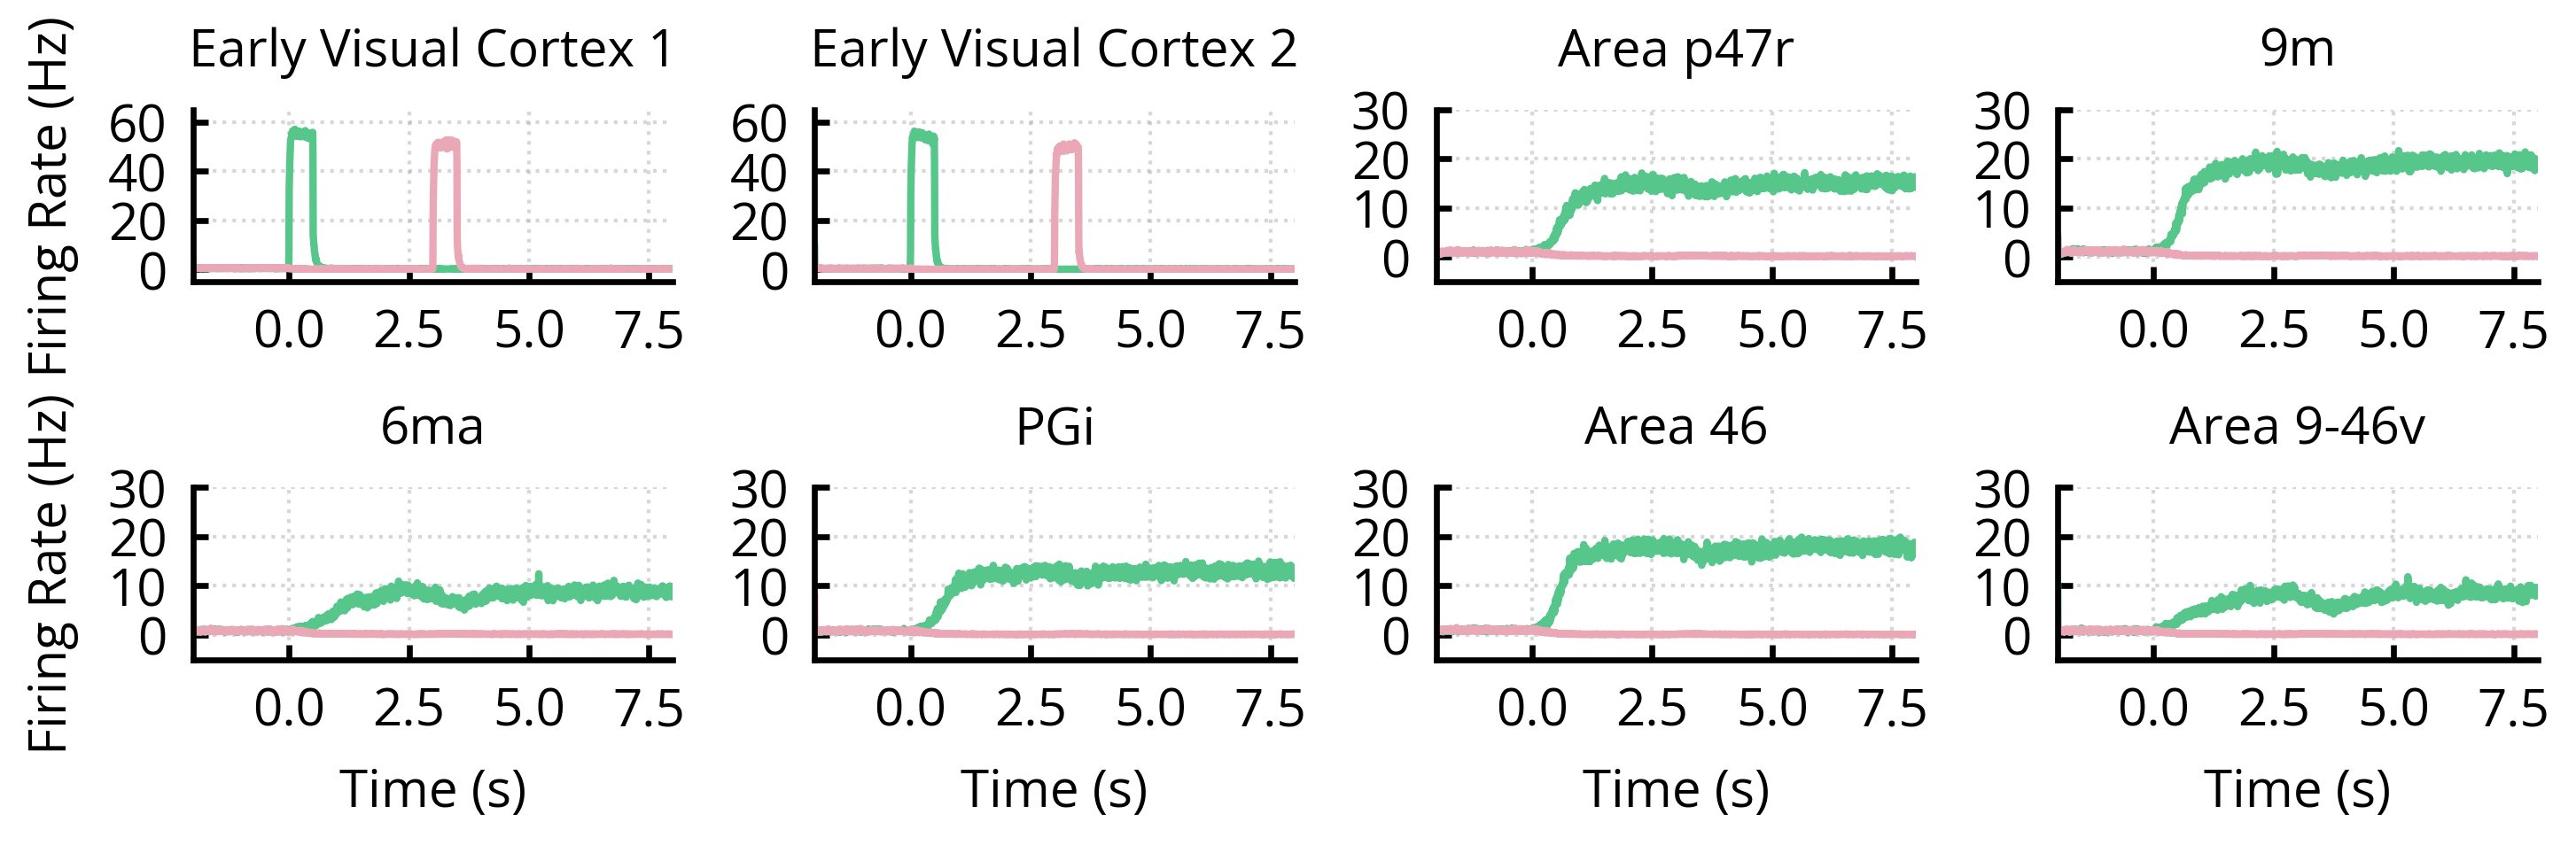

In [2]:
# Single 2x4 panel version of the plot_n_areas figure above
# 2/3 of the 18.4 cm page width by 5 cm, Open Sans at 7 pt.
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

variables = ['r_A', 'r_B']
colors = ['#56c68a', '#eaa8b7']
downsample = 10

# Same data plot_n_areas uses internally
state_history = WM_network.get_state_histories(variables)[-1]  # (n_timepoints, n_areas, n_variables)
t_down = WM_network.time_histories[-1][::downsample]

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
FIG_W = 2 / 3 * 18.4 / CM
FIG_H = 4 / CM

with mpl.rc_context(panel_style):
    # sharex: all panels have the same time axis, so only the bottom row needs tick labels
    fig, axes = plt.subplots(2, 4, figsize=(FIG_W, FIG_H),
                             constrained_layout=True, sharex=True)

    for i, (ax, area_name) in enumerate(zip(axes.flat, target_area_names)):
        area_idx = np.where(np.array(WM_network.area_names) == area_name)[0][0]
        for var_idx, var in enumerate(variables):
            data = state_history[:, area_idx, var_idx][::downsample]
            # time is shifted so that 0 is the stimulus onset, as in plot_n_areas
            ax.plot(t_down - stim_start_time, data,
                    color=colors[var_idx], linewidth=1)

        ax.set_title(area_names_for_figure[i])
        ax.set_xlim(-2, t_end - 2)
        # same rule as plot_n_areas: the two stimulated areas get the larger y range
        ax.set_ylim(-5, 65) if i < 2 else ax.set_ylim(-5, 30)

        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.grid(linestyle=':', alpha=0.5)

        # axis labels only on the outer panels, they would not fit on all eight
        if i % 4 == 0:
            ax.set_ylabel('Firing Rate (Hz)')
        if i >= 4:
            ax.set_xlabel('Time (s)')

    # no bbox_inches='tight', so the file keeps the exact 12.27 x 5 cm size
    fig.savefig('saved_plots/Supp_Figure_5/persistent_activity_grid.svg')
    plt.show()